In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.chdir("C:/Users/SEBASTIAN/Documents/Simulacion_fincas/")

In [2]:
# Configurar semilla para reproducibilidad
np.random.seed(0)

In [26]:
# Generar datos base
n = 50  # número de filas
finca = [f'Finca {i+1}' for i in range(n)]
individuos = np.random.randint(200, 1501, n)
especies = np.random.randint(10, 41, n)
hectareas = (individuos / 1000) + np.random.normal(0, 0.2, n)  # Aumentar la variabilidad
animales = np.random.choice([0, 1], n)
comunidad = np.random.choice(['Agua Azul', 'Puerto Tejada', 'Perico Negro', 'Alegrias'], n)
mercado = np.random.choice([0, 1], n)

# Correlaciones inducidas
# Ganancia correlacionada con Individuos
ganancia = (individuos * 3) + np.random.normal(0, 300, n)  # Aumentar la variabilidad

# Shannon correlacionado con Especies
shannon = (especies * 0.1) + np.random.normal(0, 0.5, n)

# Índices de diversidad correlacionados con Especies
berger_parker = (1 / especies) + np.random.normal(0, 0.01, n)  # inversamente proporcional a especies
gini_simpson = 1 - (1 / especies) + np.random.normal(0, 0.01, n)  # inversamente proporcional a especies
margalef = (especies - 1) / np.log(individuos) + np.random.normal(0, 0.1, n)  # relación directa

# Crear el DataFrame
df_corr = pd.DataFrame({
    'Finca': finca,
    'Individuos': individuos,
    'Especies': especies,
    'Hectareas': hectareas.round(2),
    'Animales': animales,
    'Comunidad': comunidad,
    'Mercado': mercado,
    'Berger-Parker': berger_parker.round(2),
    'Gini-Simpson': gini_simpson.round(2),
    'Shannon': shannon.round(2),
    'Margalef': margalef.round(2),
    'Ganancia': ganancia.round(2)
})

# Guardar en archivos CSV y texto plano
csv_file_path_corr = 'fincas_data_corr.csv'
df_corr.to_csv(csv_file_path_corr, index=False)

text_file_path_corr = 'fincas_data_corr.txt'
df_corr.to_string(buf=open(text_file_path_corr, 'w'), index=False)

print(csv_file_path_corr, text_file_path_corr)


fincas_data_corr.csv fincas_data_corr.txt


In [27]:
df= pd.read_csv("fincas_data_corr.csv", sep= ",")
df.head(3)

,Finca,Individuos,Especies,Hectareas,Animales,Comunidad,Mercado,Berger-Parker,Gini-Simpson,Shannon,Margalef,Ganancia
0,Finca 1,279,15,-0.12,1,Perico Negro,1,0.05,0.94,2.15,2.43,592.86
1,Finca 2,1449,15,1.78,0,Agua Azul,0,0.07,0.94,1.49,1.94,3912.26
2,Finca 3,1235,11,1.23,1,Alegrias,0,0.09,0.90,1.67,1.46,3309.68


In [28]:
num= df.select_dtypes(["float64", "int64"]).columns
df_num= df[num]
df_num.head(3)

,Individuos,Especies,Hectareas,Animales,Mercado,Berger-Parker,Gini-Simpson,Shannon,Margalef,Ganancia
0,279,15,-0.12,1,1,0.05,0.94,2.15,2.43,592.86
1,1449,15,1.78,0,0,0.07,0.94,1.49,1.94,3912.26
2,1235,11,1.23,1,0,0.09,0.90,1.67,1.46,3309.68


<Axes: >

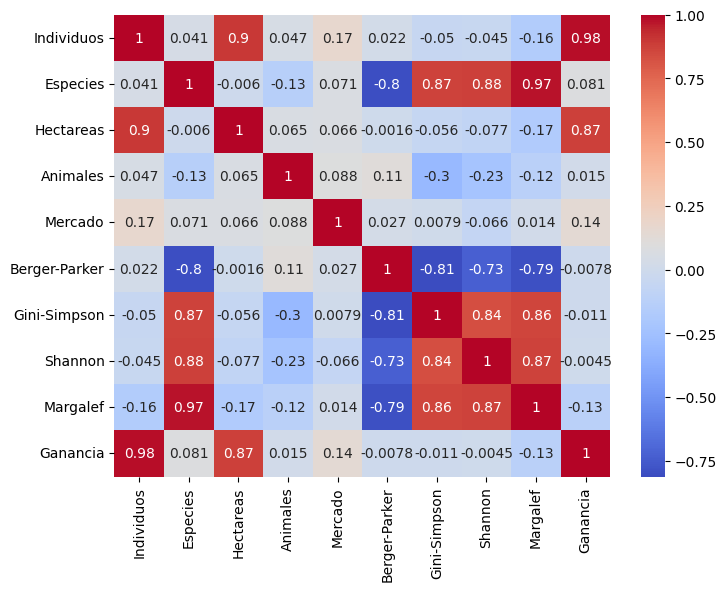

In [30]:
plt.figure(figsize=(8,6))
sns.heatmap(df_num.corr(), annot= True, cmap= "coolwarm")

In [25]:
sns.lmplot(x=df["Hectareas"], y= df["Ganancia"], data= df_num)

KeyError: "None of [Index([   0.19,    0.25,    0.28,     0.3,    0.31,    0.32,    0.34,    0.39,\n           0.4,    0.43,    0.44,    0.45,    0.52,    0.54,    0.58,    0.59,\n           0.6,    0.61,    0.66,    0.67,    0.69,     0.7,    0.85,    0.86,\n          0.89,    0.92,    1.01,    1.04,    1.05,    1.07,    1.09,    1.11,\n          1.14,    1.15,    1.16,    1.17,     1.2,    1.27,    1.28,    1.43,\n          1.45,     1.5,    1.54,  688.17,  748.32,  849.43,  891.23,  906.63,\n        923.89,  939.39, 1111.07,  1132.9, 1261.09, 1262.48, 1335.51, 1370.66,\n       1507.17, 1512.74, 1610.36,  1614.0, 1638.81, 1642.12, 1676.63, 1751.48,\n       1827.62, 1870.65, 2073.29, 2117.01, 2119.05, 2163.13,  2188.1, 2210.86,\n        2409.9, 2773.21, 2828.61, 3251.69, 3278.17, 3313.27, 3332.85, 3335.36,\n       3399.47, 3421.83, 3497.24, 3568.21, 3649.65, 3830.11, 3854.51,  3918.7,\n       4092.91,  4098.6, 4105.03, 4325.67, 4364.85],\n      dtype='float64')] are in the [columns]"